,product_name,product_url,product_type,clean_ingreds,price
0,The Ordinary Natural Moisturising Factors + HA...,https://www.lookfantastic.com/the-ordinary-nat...,Moisturiser,"['capric triglyceride', 'cetyl alcohol', 'prop...",£5.20
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,https://www.lookfantastic.com/cerave-facial-mo...,Moisturiser,"['homosalate', 'glycerin', 'octocrylene', 'eth...",£13.00
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,https://www.lookfantastic.com/the-ordinary-hya...,Moisturiser,"['sodium hyaluronate', 'sodium hyaluronate', '...",£6.20
3,AMELIORATE Transforming Body Lotion 200ml,https://www.lookfantastic.com/ameliorate-trans...,Moisturiser,"['ammonium lactate', 'c12-15', 'glycerin', 'pr...",£22.50
4,CeraVe Moisturising Cream 454g,https://www.lookfantastic.com/cerave-moisturis...,Moisturiser,"['glycerin', 'cetearyl alcohol', 'capric trigl...",£16.00


In [ ]:
import pandas as pd
df = pd.read_csv("../data/skincare_products.csv")
df.head()

In [ ]:
# Lihat tipe data di setiap kolomnya
print("Tipe data:")
print(df.dtypes)

# Memeriksa nilai kosong
print("\nNilai kosong:")
print(df.isnull().sum())

# Memeriksa duplikasi
print("\nJumlah baris duplikat:")
print(df.duplicated().sum())

# Melihat kategori jenis produk
print("\nJenis produk:")
print(df["product_type"].value_counts())


Tipe data:
product_name     object
product_url      object
product_type     object
clean_ingreds    object
price            object
dtype: object

Nilai kosong:
product_name     0
product_url      0
product_type     0
clean_ingreds    0
price            0
dtype: int64

Jumlah baris duplikat:
0

Jenis produk:
product_type
Mask           124
Body Wash      123
Cleanser       115
Moisturiser    115
Serum          113
Eye Care       100
Mist            80
Oil             76
Toner           73
Balm            61
Exfoliator      57
Bath Salts      36
Bath Oil        33
Peel            32
Name: count, dtype: int64


In [3]:
import pandas as pd

df_clean = df.copy()

for kolom in df_clean.select_dtypes(include="object").columns:
    df_clean[kolom] = df_clean[kolom].str.strip()

df_clean["price"] = pd.to_numeric(
    df_clean["price"].str.replace(r"[^\d.]", "", regex=True),
    errors="coerce"
)

print(df_clean[["product_name", "price"]].head())
print("\nTipe data setelah pembersihan:")
print(df_clean.dtypes)
print("\nHarga yang gagal dikonversi:")
print(df_clean["price"].isnull().sum())

                                        product_name  price
0  The Ordinary Natural Moisturising Factors + HA...    5.2
1      CeraVe Facial Moisturising Lotion SPF 25 52ml   13.0
2  The Ordinary Hyaluronic Acid 2% + B5 Hydration...    6.2
3          AMELIORATE Transforming Body Lotion 200ml   22.5
4                     CeraVe Moisturising Cream 454g   16.0

Tipe data setelah pembersihan:
product_name      object
product_url       object
product_type      object
clean_ingreds     object
price            float64
dtype: object

Harga yang gagal dikonversi:
0


In [4]:
print(df_clean["price"].describe())

print("\nNilai kosong:")
print(df_clean.isnull().sum())

print("\nJumlah baris duplikat:", df_clean.duplicated().sum())

count    1138.000000
mean       24.021775
std        21.770652
min         1.950000
25%         9.950000
50%        18.925000
75%        31.500000
max       230.000000
Name: price, dtype: float64

Nilai kosong:
product_name     0
product_url      0
product_type     0
clean_ingreds    0
price            0
dtype: int64

Jumlah baris duplikat: 0


In [5]:
print("Statistik harga produk:")
print(df_clean["price"].describe())

print("\nJumlah produk berdasarkan jenis:")
print(df_clean["product_type"].value_counts())

Statistik harga produk:
count    1138.000000
mean       24.021775
std        21.770652
min         1.950000
25%         9.950000
50%        18.925000
75%        31.500000
max       230.000000
Name: price, dtype: float64

Jumlah produk berdasarkan jenis:
product_type
Mask           124
Body Wash      123
Cleanser       115
Moisturiser    115
Serum          113
Eye Care       100
Mist            80
Oil             76
Toner           73
Balm            61
Exfoliator      57
Bath Salts      36
Bath Oil        33
Peel            32
Name: count, dtype: int64


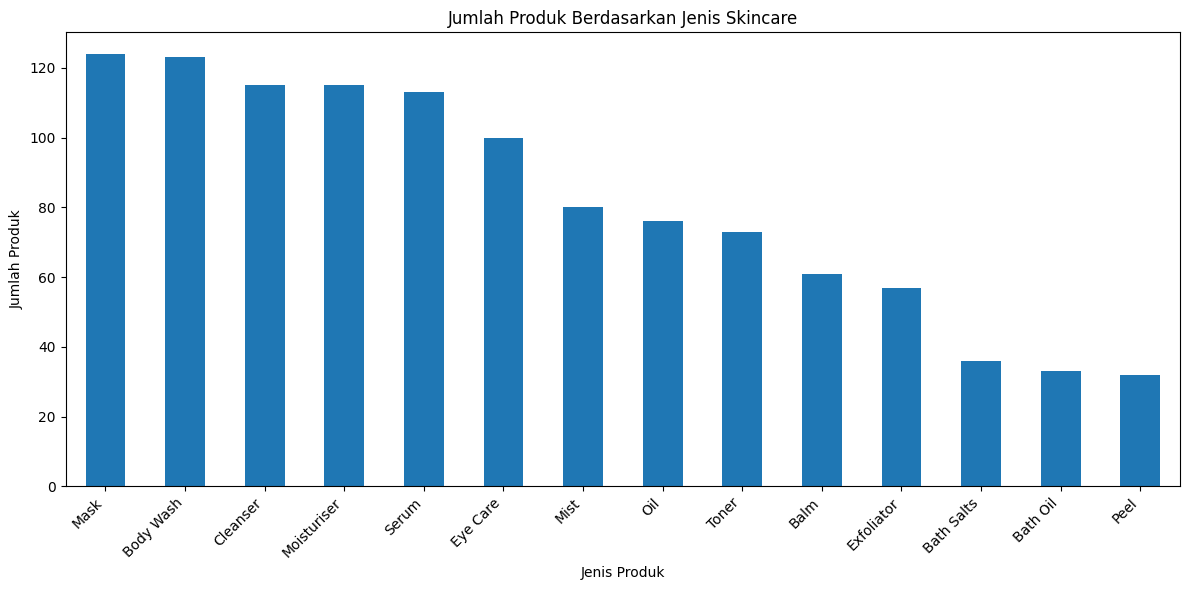

In [6]:
import matplotlib.pyplot as plt

jenis_produk = df_clean["product_type"].value_counts()

plt.figure(figsize=(12, 6))
jenis_produk.plot(kind="bar")

plt.title("Jumlah Produk Berdasarkan Jenis Skincare")
plt.xlabel("Jenis Produk")
plt.ylabel("Jumlah Produk")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

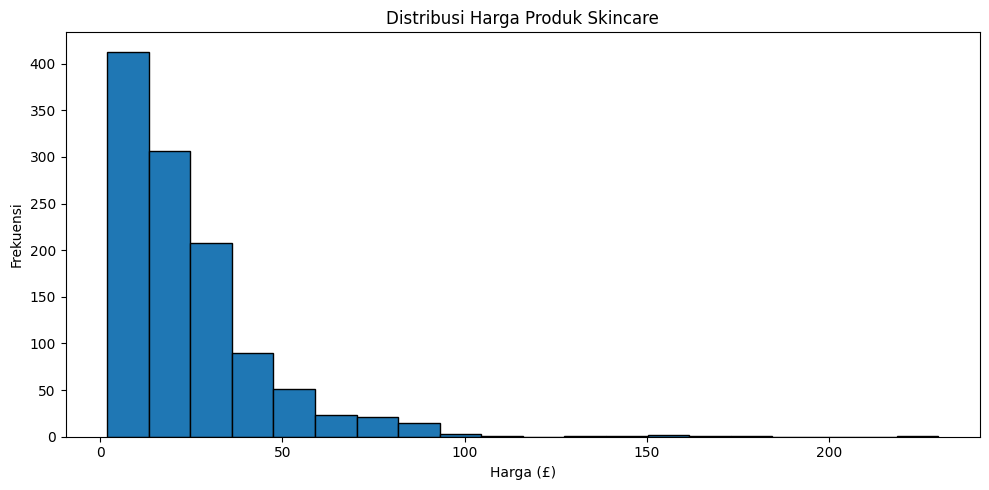

In [7]:
plt.figure(figsize=(10, 5))

plt.hist(df_clean["price"].dropna(), bins=20, edgecolor="black")

plt.title("Distribusi Harga Produk Skincare")
plt.xlabel("Harga (£)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

<Figure size 1300x600 with 0 Axes>

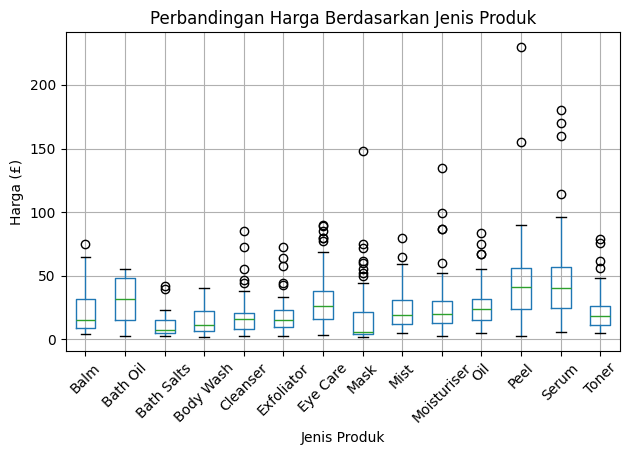

In [8]:
plt.figure(figsize=(13, 6))

df_clean.boxplot(
    column="price",
    by="product_type",
    rot=45
)

plt.title("Perbandingan Harga Berdasarkan Jenis Produk")
plt.suptitle("")
plt.xlabel("Jenis Produk")
plt.ylabel("Harga (£)")
plt.tight_layout()
plt.show()

In [9]:
df_model = df_clean.copy()

df_model = df_model.dropna(subset=["product_type"])

df_model = df_model.drop_duplicates(
    subset=["product_name", "product_type"]
)

print("Jumlah data setelah persiapan:", df_model.shape)
print("\nJumlah data kosong:")
print(df_model.isnull().sum())
print("\nContoh data:")
display(df_model.head())

Jumlah data setelah persiapan: (1138, 5)

Jumlah data kosong:
product_name     0
product_url      0
product_type     0
clean_ingreds    0
price            0
dtype: int64

Contoh data:


,product_name,product_url,product_type,clean_ingreds,price
0,The Ordinary Natural Moisturising Factors + HA...,https://www.lookfantastic.com/the-ordinary-nat...,Moisturiser,"['capric triglyceride', 'cetyl alcohol', 'prop...",5.2
1,CeraVe Facial Moisturising Lotion SPF 25 52ml,https://www.lookfantastic.com/cerave-facial-mo...,Moisturiser,"['homosalate', 'glycerin', 'octocrylene', 'eth...",13.0
2,The Ordinary Hyaluronic Acid 2% + B5 Hydration...,https://www.lookfantastic.com/the-ordinary-hya...,Moisturiser,"['sodium hyaluronate', 'sodium hyaluronate', '...",6.2
3,AMELIORATE Transforming Body Lotion 200ml,https://www.lookfantastic.com/ameliorate-trans...,Moisturiser,"['ammonium lactate', 'c12-15', 'glycerin', 'pr...",22.5
4,CeraVe Moisturising Cream 454g,https://www.lookfantastic.com/cerave-moisturis...,Moisturiser,"['glycerin', 'cetearyl alcohol', 'capric trigl...",16.0


In [10]:
X = df_model[["clean_ingreds", "price"]]
y = df_model["product_type"]

print("Jumlah fitur:", X.shape)
print("Jumlah target:", y.shape)

print("\nContoh fitur:")
display(X.head())

print("\nContoh target:")
display(y.head())

Jumlah fitur: (1138, 2)
Jumlah target: (1138,)

Contoh fitur:


,clean_ingreds,price
0,"['capric triglyceride', 'cetyl alcohol', 'prop...",5.2
1,"['homosalate', 'glycerin', 'octocrylene', 'eth...",13.0
2,"['sodium hyaluronate', 'sodium hyaluronate', '...",6.2
3,"['ammonium lactate', 'c12-15', 'glycerin', 'pr...",22.5
4,"['glycerin', 'cetearyl alcohol', 'capric trigl...",16.0



Contoh target:


0    Moisturiser
1    Moisturiser
2    Moisturiser
3    Moisturiser
4    Moisturiser
Name: product_type, dtype: object

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 910
Jumlah data testing: 228


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Mengubah nilai kosong
X_train = X_train.copy()
X_test = X_test.copy()

X_train["clean_ingreds"] = X_train["clean_ingreds"].fillna("")
X_test["clean_ingreds"] = X_test["clean_ingreds"].fillna("")

# Menggabungkan pengolahan teks dan harga
preprocessor = ColumnTransformer(
    transformers=[
        ("teks", TfidfVectorizer(max_features=1000), "clean_ingreds"),
        ("harga", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), ["price"])
    ]
)

print("Persiapan fitur teks dan harga selesai!")

Persiapan fitur teks dan harga selesai!


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Membuat model Machine Learning
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=1
    ))
])

model.fit(X_train, y_train)

print("Model Machine Learning berhasil dilatih!")

Model Machine Learning berhasil dilatih!


In [14]:
y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Model:", round(akurasi * 100, 2), "%")
print("\nLaporan Evaluasi Model:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Akurasi Model: 58.33 %

Laporan Evaluasi Model:
              precision    recall  f1-score   support

        Balm       0.88      0.58      0.70        12
    Bath Oil       0.23      0.43      0.30         7
  Bath Salts       0.64      1.00      0.78         7
   Body Wash       0.70      0.76      0.73        25
    Cleanser       0.47      0.39      0.43        23
  Exfoliator       0.50      0.36      0.42        11
    Eye Care       0.62      0.50      0.56        20
        Mask       0.74      0.80      0.77        25
        Mist       0.70      0.44      0.54        16
 Moisturiser       0.50      0.57      0.53        23
         Oil       0.62      0.67      0.65        15
        Peel       0.25      0.50      0.33         6
       Serum       0.62      0.57      0.59        23
       Toner       0.57      0.53      0.55        15

    accuracy                           0.58       228
   macro avg       0.58      0.58      0.56       228
weighted avg       0.61      0.5

In [15]:
hasil_prediksi = X_test.copy()
hasil_prediksi["Jenis Produk Sebenarnya"] = y_test
hasil_prediksi["Jenis Produk Prediksi"] = y_pred

display(hasil_prediksi.head(10))

,clean_ingreds,price,Jenis Produk Sebenarnya,Jenis Produk Prediksi
837,"['alcohol denat', 'salicylic acid', 'hamamelis...",18.00,Toner,Toner
1064,"['sodium c14-16 olefin sulfonate', 'glycerin',...",24.00,Body Wash,Body Wash
243,"['oryza sativa bran', 'vitis vinifera extract'...",29.00,Oil,Oil
981,['sodium chloride'],19.95,Bath Salts,Bath Salts
174,"['niacinamide', 'butylene glycol', 'castor oil...",52.65,Serum,Bath Oil
315,"['betula alba bark extract', 'propanediol', 'p...",6.50,Mist,Toner
396,"['lanolin', 'glycerin', 'cetearyl alcohol', 's...",15.00,Balm,Moisturiser
615,"['persea gratissima oil', 'glycerin', 'ceteary...",22.00,Eye Care,Eye Care
1068,"['paraffinum liquidum', 'cetearyl alcohol', 's...",3.00,Body Wash,Bath Salts
249,"['capric triglyceride', 'vitis vinifera extrac...",30.00,Oil,Oil


In [16]:
produk_baru = pd.DataFrame({
    "clean_ingreds": [
        "water, glycerin, niacinamide, hyaluronic acid"
    ],
    "price": [15.0]
})

# Prediksi jenis produk
prediksi = model.predict(produk_baru)

print("Prediksi jenis produk skincare:", prediksi[0])

Prediksi jenis produk skincare: Toner


In [17]:
import joblib
import os

os.makedirs("../model", exist_ok=True)

joblib.dump(model, "../model/model_skincare.pkl")

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [18]:
model_loaded = joblib.load("../model/model_skincare.pkl")

prediksi_baru = model_loaded.predict(produk_baru)

print("Hasil prediksi:", prediksi_baru[0])

Hasil prediksi: Toner
